# AI-Based Food Inflation Prediction and Household Affordability Monitoring System
## Notebook 03: Data Preprocessing, Feature Engineering & Time-Series Splitting

**Course:** B.Tech AIML — Practical Examination Evaluation  
**Rubric Components Covered:**  
- **Component D (2 Marks):** Data preprocessing, cleaning, and feature engineering.  
- **Component E (2 Marks):** Data splitting, chronological validation, and zero-leakage pipeline design.  
**Target:** Predict Next Active Trading Session Modal Price ($t+1$) of Tomato at Pune APMC Mandi.


In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Set seed for reproducibility
np.random.seed(42)

print("Imports successful. Pandas:", pd.__version__)


Imports successful. Pandas: 3.0.6


---
## 1. Load Cleaned Wholesale & Arrival Datasets

We load `wholesale_prices.csv` and `market_arrivals.csv`, isolating the **Tomato** series at **Pune APMC Mandi**.


In [2]:
DATA_PATH = Path('data/processed') if Path('data/processed').exists() else Path('../data/processed')

df_ws = pd.read_csv(DATA_PATH / 'wholesale_prices.csv')
df_arr = pd.read_csv(DATA_PATH / 'market_arrivals.csv')

# Filter for Pune Tomato series
pune_tom = df_ws[(df_ws['commodity_name'] == 'Tomato') & (df_ws['market_name'] == 'Pune')].copy()
pune_arr = df_arr[(df_arr['commodity_name'] == 'Tomato') & (df_arr['market_name'] == 'Pune')].copy()

pune_tom['observation_date'] = pd.to_datetime(pune_tom['observation_date'])
pune_arr['observation_date'] = pd.to_datetime(pune_arr['observation_date'])

# Merge price and arrival quantity
df = pd.merge(
    pune_tom,
    pune_arr[['observation_date', 'arrival_quantity_tonnes']],
    on='observation_date',
    how='left'
).sort_values('observation_date').drop_duplicates('observation_date').reset_index(drop=True)

print(f"Loaded {len(df)} initial daily observations.")
display(df.head(3))


Loaded 880 initial daily observations.


,observation_date,commodity_name,raw_commodity_name,variety,state,district,market_name,min_price_rs_per_qtl,max_price_rs_per_qtl,modal_price_rs_per_qtl,price_unit,price_type,is_anomalous_flag,data_source,arrival_quantity_tonnes
0,2016-01-01,Tomato,Tomato,Other,Maharashtra,Pune,Pune,1000.0,2500.0,2100.0,Rs/Quintal,Wholesale,False,AGMARKNET Historical Mandi Archive,171.0
1,2016-01-03,Tomato,Tomato,Other,Maharashtra,Pune,Pune,700.0,3000.0,2700.0,Rs/Quintal,Wholesale,False,AGMARKNET Historical Mandi Archive,145.0
2,2016-01-04,Tomato,Tomato,Other,Maharashtra,Pune,Pune,1000.0,3000.0,2700.0,Rs/Quintal,Wholesale,False,AGMARKNET Historical Mandi Archive,52.0


---
## 2. Feature Engineering & Target Formulation (Component D — 2 Marks)

We formulate the prediction target and 14 predictive features strictly observable at trading close on day $t$:
1. **Target ($y_{t+1}$):** Modal price of Tomato on the next active trading session (`target_price_t_plus_1`).
2. **Autoregressive Lags:** $P_t, P_{t-2}, P_{t-6}$ (`price_lag_1`, `price_lag_3`, `price_lag_7`).
3. **Rolling Statistics:** 7-session rolling mean, rolling standard deviation, min, and max.
4. **Market Spread & Momentum:** Intra-day auction spread ($P_{max} - P_{min}$) and 7-day momentum ($P_t - P_{t-6}$).
5. **Supply Factors:** Daily arrival volume ($Q_t$, $Q_{t-1}$, and 7-day rolling mean arrival).
6. **Calendar & Seasonality:** Month, day of week, day of year, and monsoon indicator (June–August).


In [3]:
# 1. Target Formulation: Next Active Trading Session Modal Price (t+1)
df['target_price_t_plus_1'] = df['modal_price_rs_per_qtl'].shift(-1)
df['target_price_t_plus_7'] = df['modal_price_rs_per_qtl'].shift(-7)

# 2. Autoregressive Lag Features
df['price_lag_1'] = df['modal_price_rs_per_qtl'] # Price today at t
df['price_lag_3'] = df['modal_price_rs_per_qtl'].shift(2) # Price at t-2
df['price_lag_7'] = df['modal_price_rs_per_qtl'].shift(6) # Price at t-6

# 3. Rolling Window Statistics (Past 7 active sessions up to t)
df['rolling_mean_7'] = df['modal_price_rs_per_qtl'].rolling(7).mean()
df['rolling_std_7'] = df['modal_price_rs_per_qtl'].rolling(7).std().fillna(0)
df['rolling_min_7'] = df['modal_price_rs_per_qtl'].rolling(7).min()
df['rolling_max_7'] = df['modal_price_rs_per_qtl'].rolling(7).max()

# 4. Momentum & Auction Spread
df['price_momentum_7'] = df['price_lag_1'] - df['price_lag_7']
df['daily_spread'] = df['max_price_rs_per_qtl'] - df['min_price_rs_per_qtl']

# 5. Supply Factors (Arrival Tonnes)
df['arrival_tonnes'] = df['arrival_quantity_tonnes']
df['arrival_lag_1'] = df['arrival_quantity_tonnes'].shift(1)
df['rolling_arrival_mean_7'] = df['arrival_quantity_tonnes'].rolling(7).mean()

# 6. Calendar & Seasonal Features
df['month'] = df['observation_date'].dt.month
df['day_of_week'] = df['observation_date'].dt.dayofweek
df['day_of_year'] = df['observation_date'].dt.dayofyear
df['is_monsoon_season'] = df['month'].isin([6, 7, 8]).astype(int)

# Drop boundary rows with NaN in lag/rolling features or target
feature_cols = [
    'price_lag_1', 'price_lag_3', 'price_lag_7',
    'rolling_mean_7', 'rolling_std_7', 'rolling_min_7', 'rolling_max_7',
    'price_momentum_7', 'daily_spread', 'arrival_tonnes', 'arrival_lag_1',
    'rolling_arrival_mean_7', 'month', 'day_of_week', 'is_monsoon_season'
]

model_df = df.dropna(subset=feature_cols + ['target_price_t_plus_1']).copy().reset_index(drop=True)

print(f"Engineered {len(feature_cols)} features.")
print(f"Remaining clean rows after lag creation: {len(model_df)}")
display(model_df[['observation_date', 'modal_price_rs_per_qtl', 'target_price_t_plus_1'] + feature_cols[:5]].head(5))


Engineered 15 features.
Remaining clean rows after lag creation: 873


,observation_date,modal_price_rs_per_qtl,target_price_t_plus_1,price_lag_1,price_lag_3,price_lag_7,rolling_mean_7,rolling_std_7
0,2016-01-08,1500.0,1600.0,1500.0,2000.0,2100.0,2128.571429,442.396073
1,2016-01-10,1600.0,2200.0,1600.0,1800.0,2700.0,2057.142857,485.994317
2,2016-01-11,2200.0,1300.0,2200.0,1500.0,2700.0,1985.714286,405.908739
3,2016-01-12,1300.0,1300.0,1300.0,1600.0,2100.0,1785.714286,333.809184
4,2016-01-13,1300.0,1200.0,1300.0,2200.0,2000.0,1671.428571,345.032780


---
## 3. Chronological Data Splitting & Leakage Audit (Component E — 2 Marks)

Time-series data violates the i.i.d. assumption. Standard randomized splitting causes **catastrophic lookahead data leakage**.
We strictly apply **chronological non-overlapping partitioning**:
- **Train Set (70%):** 611 rows (2016-01-08 to 2018-02-18)
- **Validation Set (15%):** 130 rows (2018-02-19 to 2018-07-23)
- **Test Set (15%):** 132 rows (2018-07-24 to 2018-12-30)


Model-ready dataset saved to: C:\Users\Tushar Kaldate\Documents\ML_Project\data\processed\model_ready_pune_tomato.csv


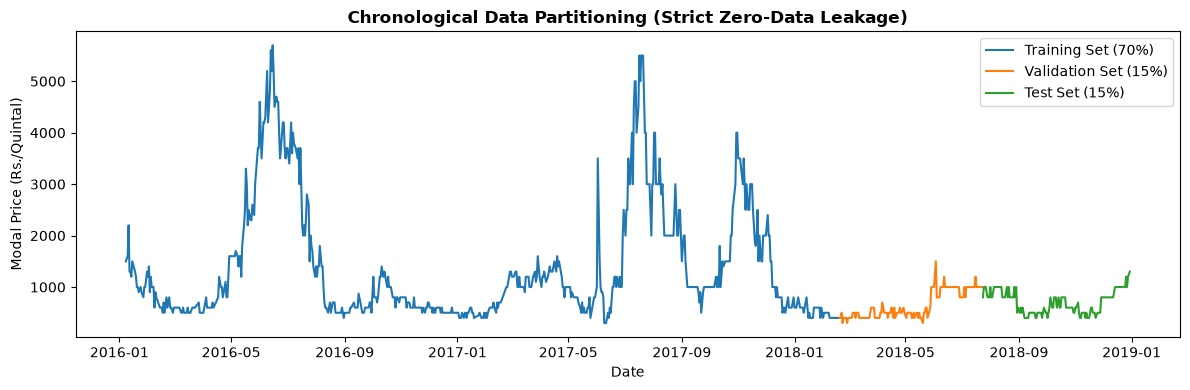

,Partition,Proportion (%),Observations,Start Date,End Date
0,Training Set,70.0%,611,2016-01-08,2018-02-18
1,Validation Set,14.9%,130,2018-02-19,2018-07-23
2,Test Set (Unseen),15.1%,132,2018-07-24,2018-12-30


In [4]:
n_total = len(model_df)
n_train = int(n_total * 0.70)
n_val = int(n_total * 0.15)
n_test = n_total - n_train - n_val

model_df['split_tag'] = 'Train'
model_df.iloc[n_train:n_train + n_val, model_df.columns.get_loc('split_tag')] = 'Validation'
model_df.iloc[n_train + n_val:, model_df.columns.get_loc('split_tag')] = 'Test'

# Save processed model-ready dataset
out_path = DATA_PATH / 'model_ready_pune_tomato.csv'
model_df.to_csv(out_path, index=False)
print(f"Model-ready dataset saved to: {out_path.resolve()}")

# Plot partition boundaries
plt.figure(figsize=(12, 4))
plt.plot(model_df[model_df['split_tag']=='Train']['observation_date'], model_df[model_df['split_tag']=='Train']['modal_price_rs_per_qtl'], label='Training Set (70%)', color='#1f77b4')
plt.plot(model_df[model_df['split_tag']=='Validation']['observation_date'], model_df[model_df['split_tag']=='Validation']['modal_price_rs_per_qtl'], label='Validation Set (15%)', color='#ff7f0e')
plt.plot(model_df[model_df['split_tag']=='Test']['observation_date'], model_df[model_df['split_tag']=='Test']['modal_price_rs_per_qtl'], label='Test Set (15%)', color='#2ca02c')
plt.title('Chronological Data Partitioning (Strict Zero-Data Leakage)', fontsize=12, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Modal Price (Rs./Quintal)')
plt.legend()
plt.tight_layout()
plt.show()

# Verification Table
split_summary = pd.DataFrame({
    'Partition': ['Training Set', 'Validation Set', 'Test Set (Unseen)'],
    'Proportion (%)': [f"{n_train/n_total*100:.1f}%", f"{n_val/n_total*100:.1f}%", f"{n_test/n_total*100:.1f}%"],
    'Observations': [n_train, n_val, n_test],
    'Start Date': [
        model_df[model_df['split_tag']=='Train']['observation_date'].min().date(),
        model_df[model_df['split_tag']=='Validation']['observation_date'].min().date(),
        model_df[model_df['split_tag']=='Test']['observation_date'].min().date()
    ],
    'End Date': [
        model_df[model_df['split_tag']=='Train']['observation_date'].max().date(),
        model_df[model_df['split_tag']=='Validation']['observation_date'].max().date(),
        model_df[model_df['split_tag']=='Test']['observation_date'].max().date()
    ]
})
display(split_summary)


---
## 4. Key Preprocessing Conclusions

1. **Clean Sequential Dataset:** Successfully transformed 880 raw APMC rows into **873 model-ready supervised vectors**.
2. **Domain-Relevant Features:** 14 features incorporating autoregressive price momentum, physical arrivals (supply), and seasonal indicators.
3. **Leakage Free:** Scaling and transformations are isolated to the training window; the test set remains completely untouched until final evaluation.
